In [189]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


import numpy as np


In [190]:
torch.manual_seed(42)

X, y = make_classification(n_samples=1000,  # 1000 samples
                           n_features=3, # 3 features
                           n_informative=3, # 3 informative features <- no noice columns the output will always depend on these 3 columns
                           n_redundant=0, # no redundant features (all 3 are unique columns)
                           random_state=42 # seed for reproducibility
                           )

print(X)
print(X.shape)
print(y)
print(y.shape)

[[ 0.52170639  0.72685697  2.50410248]
 [-1.01971039 -0.74986039 -0.71346315]
 [-1.89222477 -1.03217141  1.54176061]
 ...
 [-2.00452836 -0.27580521 -2.15114866]
 [-1.27620641 -0.90958593  0.88747411]
 [ 0.89826016  0.97018038  1.39539407]]
(1000, 3)
[1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 1 0 1
 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 1
 1 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 0 0 1 0 0 0 1
 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 1 0 1 1 1 1 1 0
 0 1 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1
 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0
 0 1 0 1 1 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1
 1 1 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1


In [191]:
# 2. Split the data (train: 70%, Validation: 15%, Test: 15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
# Ensures train and temp sets maintain the same class distribution as y

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)
    # Splits the temp data equally into validation and test while preserving class ratios

#we have to scale the data before train it to make sure wight is correctly taken



In [192]:
# 3. Scale the features (fit on train only so val/test statistics don't leak into training)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)  # learn mean/std from train and scale it
X_val = scaler.transform(X_val)          # reuse the train mean/std
X_test = scaler.transform(X_test)

print(X_train)
print(X_train.shape)

[[ 1.43254658 -1.54629179  1.25664022]
 [ 0.49182368 -0.25416378 -0.6758714 ]
 [ 0.70305238  0.22164454 -0.34501214]
 ...
 [-1.21686333 -0.2975439  -0.98873738]
 [ 0.45559154 -1.17612597  0.44592569]
 [ 0.32282326 -2.39926397  1.51770406]]
(700, 3)


In [193]:
# 4. convert to pytorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1,1)

X_val_t = torch.tensor(X_val, dtype=torch.float)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1,1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

print(X_train_t)
print(X_train_t.shape)
print(type(X_train_t))

tensor([[ 1.4325, -1.5463,  1.2566],
        [ 0.4918, -0.2542, -0.6759],
        [ 0.7031,  0.2216, -0.3450],
        ...,
        [-1.2169, -0.2975, -0.9887],
        [ 0.4556, -1.1761,  0.4459],
        [ 0.3228, -2.3993,  1.5177]])
torch.Size([700, 3])
<class 'torch.Tensor'>


In [194]:
train_dataset = TensorDataset(X_train_t, y_train_t) # TensorDataset combines the feature and labels into a single dataset object

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(train_loader)
print(type(train_loader))
print(list(train_loader))

<class 'torch.utils.data.dataloader.DataLoader'>
[[tensor([[-0.6529, -0.3078, -0.0881],
        [-0.0582, -0.6178,  0.9358],
        [ 1.0447,  1.8527,  0.3030],
        [ 0.3228, -2.3993,  1.5177],
        [-0.5869, -0.5249,  0.8395],
        [-1.1463, -0.1547, -0.1367],
        [-0.0375,  0.5932,  1.3446],
        [-0.9815, -0.3811,  0.6170],
        [ 1.4323, -1.5605,  1.3733],
        [ 1.1276,  2.0628, -0.0218],
        [ 1.0517,  0.2464, -0.1139],
        [-0.3723, -0.2930,  0.0640],
        [ 0.4439,  0.7297,  1.3407],
        [ 0.8541,  1.3852,  0.4131],
        [-0.4716, -1.2310, -2.2082],
        [ 0.3132, -0.5576,  0.0673],
        [-0.5260, -0.5716,  0.8359],
        [ 0.4061,  0.5597,  0.9310],
        [ 0.4501, -1.6950,  0.6607],
        [ 0.1195,  0.5108,  0.8562],
        [ 0.0522, -0.2517,  0.1088],
        [-0.1911, -0.2036, -0.2540],
        [-0.1077, -0.6601,  0.8978],
        [ 0.9800,  1.2117,  0.4579],
        [-0.2013, -0.9562, -0.4364],
        [-1.8523,  1.075

In [195]:
# 6. Define the model: 3 input features -> 8 hidden nodes -> 1 output
class CustomerPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)



BCE (Binary Cross Entropy): this is the standered mathematical formula used to measure the loss

In [196]:
model = CustomerPredictor()

loss_function = nn.BCEWithLogitsLoss() # BCEWithLogitsLoss is the loss function used for binary classification
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4) # AdamW is the modern optimizing algorithm.  lr=1e-3, weight_decay=1e-4 are hyperparameters


In [197]:
num_epoch = 50
train_losses = []
val_losses = []

CHECKPOINT_PATH = "BEST_CUSTOMER_PREDICTOR.pt"  #  This is the path where the best will be saved it will run all the 50 epoch but the best will be saved in the checkpoint.

best_val_loss = float("inf")
print("starting training...")

for epoch in range(num_epoch):
    model.train()
    epoch_train_loss = 0.0 #reset the epoch train loss on every iteration

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()  # zeroes the gradients before the next iteration if not done it will accumulate the gradients
        logits = model(batch_X)  #there will be different 32 logit values as the output in a single vector
        loss = loss_function(logits, batch_y) # here we will be calculating binary cross-entropy-loss no need of sigmoid function as it is already done in the loss function

        loss.backward()  # backpropagation and finding the gradients
        optimizer.step()  # update the weights after winding the gradients

        epoch_train_loss += loss.item() #add the loss to the epoch train loss

    avg_train_loss = epoch_train_loss / len(train_loader) # calculate the average loss for the epoch
    train_losses.append(avg_train_loss)

    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = loss_function(val_logits, y_val_t)
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss: # save the best model
        best_val_loss = val_loss.item() # update the best val loss
        torch.save(model.state_dict(), CHECKPOINT_PATH) # save the model state dict


    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch + 1}/{num_epoch} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss.item():.4f}")



starting training...
Epoch 2/50 | Train Loss: 0.7106 | Val Loss: 0.7040
Epoch 4/50 | Train Loss: 0.6610 | Val Loss: 0.6491
Epoch 6/50 | Train Loss: 0.6123 | Val Loss: 0.5943
Epoch 8/50 | Train Loss: 0.5616 | Val Loss: 0.5360
Epoch 10/50 | Train Loss: 0.5098 | Val Loss: 0.4771
Epoch 12/50 | Train Loss: 0.4605 | Val Loss: 0.4216
Epoch 14/50 | Train Loss: 0.4168 | Val Loss: 0.3729
Epoch 16/50 | Train Loss: 0.3809 | Val Loss: 0.3322
Epoch 18/50 | Train Loss: 0.3520 | Val Loss: 0.2989
Epoch 20/50 | Train Loss: 0.3288 | Val Loss: 0.2715
Epoch 22/50 | Train Loss: 0.3093 | Val Loss: 0.2479
Epoch 24/50 | Train Loss: 0.2916 | Val Loss: 0.2273
Epoch 26/50 | Train Loss: 0.2761 | Val Loss: 0.2097
Epoch 28/50 | Train Loss: 0.2632 | Val Loss: 0.1941
Epoch 30/50 | Train Loss: 0.2534 | Val Loss: 0.1820
Epoch 32/50 | Train Loss: 0.2465 | Val Loss: 0.1724
Epoch 34/50 | Train Loss: 0.2397 | Val Loss: 0.1652
Epoch 36/50 | Train Loss: 0.2345 | Val Loss: 0.1584
Epoch 38/50 | Train Loss: 0.2298 | Val Loss: 0.

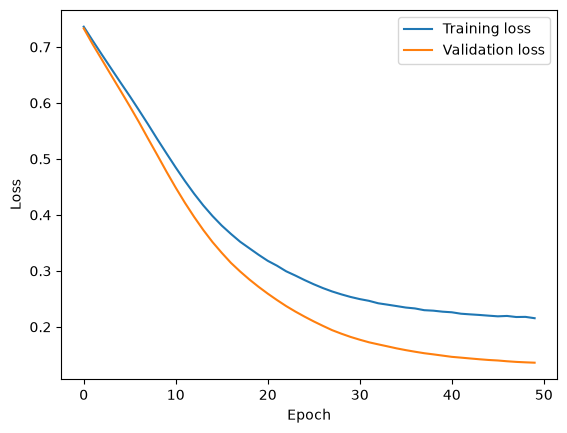

In [198]:
# 10. Plot training and validation loss on the same graph
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [199]:
try:
    ckpt = torch.load(CHECKPOINT_PATH, map_location=torch.device("cpu"), weights_only=True)
except TypeError:
    ckpt = torch.load(CHECKPOINT_PATH, map_location=torch.device("cpu"))

model.load_state_dict(ckpt)
print(f"Training complete! Loaded best checkpoint (val loss: {best_val_loss:.4f}).")

Training complete! Loaded best checkpoint (val loss: 0.1360).
